# 5. Iterative Computation: Exercise

Name: Xiuning Zhang

$$ % Latex macros
\newcommand{\mat}[1]{\begin{pmatrix} #1 \end{pmatrix}}
\newcommand{\p}[2]{\frac{\partial #1}{\partial #2}}
\newcommand{\b}[1]{\boldsymbol{#1}}
\newcommand{\w}{\boldsymbol{w}}
\newcommand{\x}{\boldsymbol{x}}
\newcommand{\y}{\boldsymbol{y}}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Newton's method

1. Define a function of your interest and find the solutions for $f(x)=0$ by Newton's method and quasi Newton's method.

2. Define m functions in m dimensional space (e.g. m=2) and find solutions for f_i(\b{x})=\b{0}$

In [7]:
def poly(x, a):
    """Polynomial a[0] + a[1]*x + ... + a[n]*x**n"""
    n = len(a)  # order+1
    xp = np.array([x**i for i in range(n)])  # 1, x,.. x**(n-1)
    y = a @ xp
    return y

def d_poly(x, a):
    """Derivative of polynomial a[1] + 2*a[2]*x + ... + n*a[n]*x**(n-1)"""
    b = np.arange(len(a))*a
    return poly(x, b[1:])

def newton(f, df, x0, a, target=1e-6, maxstep=20):
    """Newton's method.
        f, df: function and its derivative
        x: initial guess
        a: parameter for f(x,a)
        target: accuracy target"""
    x = np.zeros(maxstep+1)
    y = np.zeros(maxstep)
    x[0] = x0
    for i in range(maxstep):
        y[i] = f(x[i],a)
        if abs(y[i]) < target:
            break  # converged!
        x[i+1] = x[i] - y[i]/df(x[i],a)    # new x
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

def qnewton(f, x0, x1, a, target=1e-6, maxstep=20):
    """Quasi-Newton's method.
        f: return f
        x: initial guess
        x0, x1: initial guess at two points
        *args: parameter for f(x,*args)
        target: accuracy target"""
    x = np.zeros(maxstep+2)
    y = np.zeros(maxstep+1)
    x[0], x[1] = x0, x1
    y[0] = f(x[0], a)
    for i in range(1, maxstep+1):
        y[i] = f(x[i], a)
        if abs(y[i]) < target:
            break  # converged!
        x[i+1] = x[i] - y[i]*(x[i]-x[i-1])/(y[i] - y[i-1])    # new x
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

In [5]:
newton(poly, d_poly, 0, [-3, -2, 1])

(array([ 0.        , -1.5       , -1.05      , -1.00060976, -1.00000009]),
 array([-3.00000000e+00,  2.25000000e+00,  2.02500000e-01,  2.43939619e-03,
         3.71689188e-07]))

In [8]:
qnewton(poly, 0, 1, [-3, -2, 1])

(array([ 0.        ,  1.        , -3.        ,  0.        , -0.6       ,
        -1.15384615, -0.98360656, -0.99939043, -1.00000251, -1.        ]),
 array([-3.00000000e+00, -4.00000000e+00,  1.20000000e+01, -3.00000000e+00,
        -1.44000000e+00,  6.39053254e-01, -6.53050255e-02, -2.43790944e-03,
         1.00356202e-05, -1.52958490e-09]))

In [9]:
def mpoly(x, A):
    """multiple n dim p order polynomials
    a0 + a1*x1 +...+ an*xn + a_n+1*x1**2 +...+ a_2n*xn**2 + ... +a_pn*xn**p
    x: n or n*k
    A: m*(n*p+1)
    """
    n = len(x)   # input dimension
    p = (A.shape[1]-1)//n  # polynomial order
    xp = np.concatenate([x**i for i in range(p+1)])  # x**0=1
    #print(xp)
    return A @ xp[n-1:]  # only one 1

def dmpoly(x, A):
    """ Jacobian of multiple n dim p order plynomials
    a0 + a1*x1 +...+ an*xn + a_n+1*x1**2 +...+ a_2n*xn**2 + ... +a_pn*xn**p
    x: n or n*k
    A: m*(n*p+1)
    J = [[a[1] + 2*a[3]*x[0]+ a[5]*x[1], a[2] + 2*a[4]*x[1] + a[5]*x[0]]
    """
    n = len(x)   # input dim
    m = A.shape[0]   # output dim
    p = (A.shape[1]-1)//n  # polynomial order
    Jc = np.zeros((n,m))  # one column of Jacobian
    for i in range(n):  #differentiate by xi: ai + 2*a_n+i +...+p*a_(p-1)n+i
        Ai = np.array([j*A[:,(j-1)*n+i+1] for j in range(1,p+1)]).T
        Jc[i] = mpoly(np.array([x[i]]), Ai)  # for input dimemsion i
        #print(Ai, Jc[i])
    J = np.vstack(Jc).T  # merge as a matrix
    return J

def mnewton(f, J, x0, a, target=1e-6, maxstep=20):
    """Newton's method.
        f: the function to satisfy f(x)=0
        J; Jacobian df_i/dx_j
        x0: initial guess
        a: parameter for f(x,a), J(x,a)
        target: accuracy target"""
    n = len(x0)  # dimension
    x = np.zeros((maxstep+1, n))
    y = np.zeros((maxstep, n))
    x[0] = x0
    for i in range(maxstep):
        y[i] = f(x[i], a)
        if  sum(abs(y[i])) < target:
            break  # converged!
        x[i+1] = x[i] - np.linalg.inv(J(x[i], a))@y[i]
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

(np.float64(-2.0), np.float64(2.0), np.float64(-2.0), np.float64(2.0))

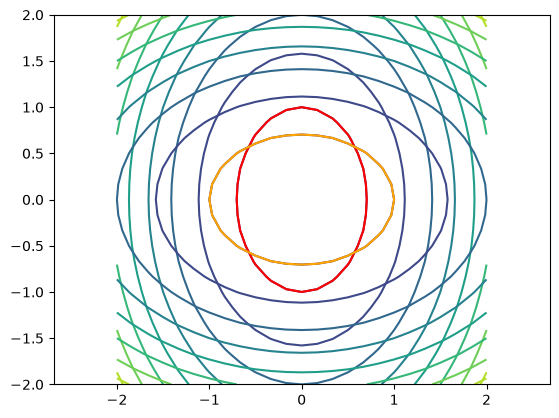

In [13]:
m = 25
x = np.linspace(-2, 2, m)
X, Y = np.meshgrid(x, x)
XY = np.array([X.ravel(),Y.ravel()])
Z = mpoly(XY, np.array([[-1,0,0,2,1],[-1,0,0,1,2]]))
Z = Z.reshape((2,m,m))
plt.contour(X, Y, Z[0]); plt.contour(X, Y, Z[0], levels=[0], colors='red')
plt.contour(X, Y, Z[1]); plt.contour(X, Y, Z[1], levels=[0], colors='orange')
plt.axis('equal')

In [23]:
mnewton(mpoly, dmpoly, np.array([0.5,1]), np.array([[-1,0,0,2,1],[-1,0,0,1,2]]))

(array([[0.5       , 1.        ],
        [0.58333333, 0.66666667],
        [0.57738095, 0.58333333],
        [0.57735027, 0.57738095],
        [0.57735027, 0.57735027]]),
 array([[5.00000000e-01, 1.25000000e+00],
        [1.25000000e-01, 2.29166667e-01],
        [7.01530612e-03, 1.39243197e-02],
        [3.54327218e-05, 7.08626194e-05],
        [9.41408063e-10, 1.88281635e-09]]))

In [19]:
def broyden(f, x0, x1, a, target=1e-6, maxstep=20):
    """Broyden's method.
        f: the function to satisfy f(x)=0
        x0, x1: initial guess
        a: parameter for f(x,a)
        target: accuracy target"""
    n = len(x0)  # dimension
    x = np.zeros((maxstep+2, n))
    y = np.zeros((maxstep+1, n))
    x[0], x[1] = x0, x1
    y[0] = f(x[0], a)
    Ji = np.eye(n)  # Inverse Jacobian estimate
    for i in range(1,maxstep+1):
        y[i] = f(x[i], a)
        if  sum(abs(y[i])) < target:
            break  # converged!
        dx = x[i] - x[i-1]
        df = y[i] - y[i-1]
        #Ji = Ji + np.outer((dx - Ji@df),(dx - Ji@df).T)/((dx - Ji@df).T@df)  # SR1 method
        Ji = Ji + np.outer((dx - Ji@df),(dx.T@Ji))/(dx@Ji@df)
        #print(x[i], Ji)
        x[i+1] = x[i] - Ji@y[i]
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

In [22]:
broyden(mpoly, np.array([0.5,1]), np.array([1.5,1]), np.array([[-1,0,0,2,1],[-1,0,0,1,2]]))

(array([[0.5       , 1.        ],
        [1.5       , 1.        ],
        [0.375     , 0.        ],
        [0.51217506, 0.38170451],
        [0.64694628, 0.87427916],
        [0.56414681, 0.52894033],
        [0.57516836, 0.56673353],
        [0.57784996, 0.57791481],
        [0.57751569, 0.57737991],
        [0.57741231, 0.5773636 ],
        [0.57734843, 0.57734987],
        [0.57735027, 0.57735027]]),
 array([[ 5.00000000e-01,  1.25000000e+00],
        [ 4.50000000e+00,  3.25000000e+00],
        [-7.18750000e-01, -8.59375000e-01],
        [-3.29655089e-01, -4.46280047e-01],
        [ 6.01443024e-01,  9.47267586e-01],
        [-8.36988869e-02, -1.22182633e-01],
        [-1.71758141e-02, -2.68075624e-02],
        [ 1.80667176e-03,  1.88162307e-03],
        [ 4.16298455e-04,  2.59493874e-04],
        [ 1.58672599e-04,  1.02420343e-04],
        [-4.70849691e-06, -3.03910738e-06],
        [-3.48221341e-10, -1.98606021e-10]]))

## 2. Bifurcation and Chaos
A value of $x_k$ that stays unchanged after applying a map $f$ to it, i.e.

$$x_k = f(x_k) = x_{k+1}$$

is called a *fixed point* of $f$.

Let us consider the logistic map

$$ x_{k+1} = a x_k(1 - x_k) $$

A *bifurcation diagram* is a plot of trajectories versus a parameter.  
draw the bifurcation diagram for parameter $a$ $(1 \le a \le 4)$, like below:  
![bifurcation](https://github.com/oist/iSciComp/blob/master/figures/bifurcation.png?raw=1)

Hint:
* Use the `logistic()` and `iterate()` functions from the previous lecture.
* For each value of $a$, show the trajectory (i.e., the values that $x_k$ took over some iterations) of the map after an initial transient.
* Since $x_k$ is 1D, you can plot the trajectory on the y axis. For example, take 200 points in $1 \le a \le 4$, run 1000 step iterations for each $a$, and plot $x$ after skipping first 100 steps.

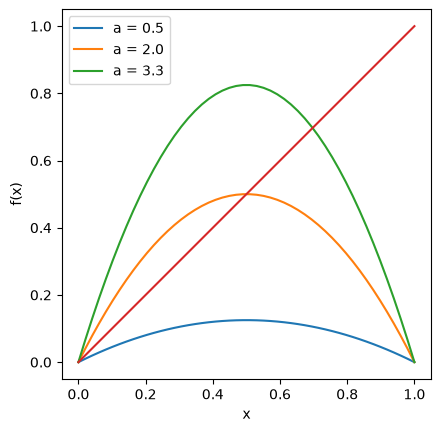

In [3]:
def logistic(x, a):
    """logistic map: f(x) = a*x*(1-x)"""
    return a*x*(1 - x)

x = np.linspace(0, 1, 50)
# plot with different levels of a
A = np.array([0.5, 2, 3.3])
leg = []
for a in A:
    y = logistic(x, a)
    plt.plot(x, y)
    leg.append('a = {}'.format(a))
plt.legend(leg)
plt.plot([0,1], [0,1])  # x=f(x) line
plt.xlabel('x'); plt.ylabel('f(x)')
plt.axis('square');

In [10]:
def fixed_point(a):
    x = (a-1)/a
    if a < 1:
        print(0)
    else:
        print(0, x)

fixed_point(0.5)
fixed_point(2)
fixed_point(3.3)

0
0 0.5
0 0.6969696969696969


In [4]:
def iterate(f, x0, a, steps=100):
    """x0: initial value
        a: parameter to f(x,a)"""
    x = np.zeros(steps+1)
    x[0] = x0
    for k in range(steps):
        x[k+1] = f(x[k], a)
    return x

def cobsplot(x):
    """cobsplot of trajectory x"""
    plt.plot([0,1], [0,1])  # x=f(x) line
    x2 = np.repeat(x, 2)  # duplicate items
    plt.plot(x2[:-1], x2[1:], lw=0.5) # (x0,x1), (x1,x1), (x1,x2),...
    plt.xlabel('$x_k$'); plt.ylabel('$x_{k+1}$');
    plt.axis('square');


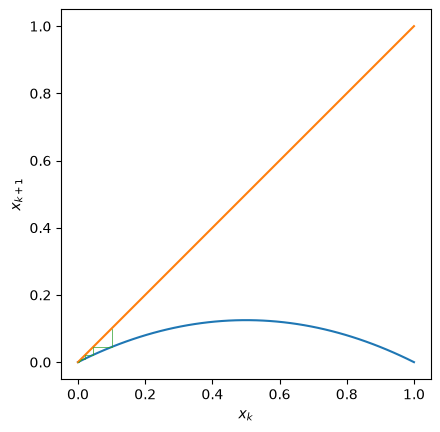

In [6]:
a = 0.5
xt = iterate(logistic, 0.1, a, 200)
plt.plot(x, logistic(x, a))  # plot the map
cobsplot(xt)  # plot the trajectory

x = 0 is stable

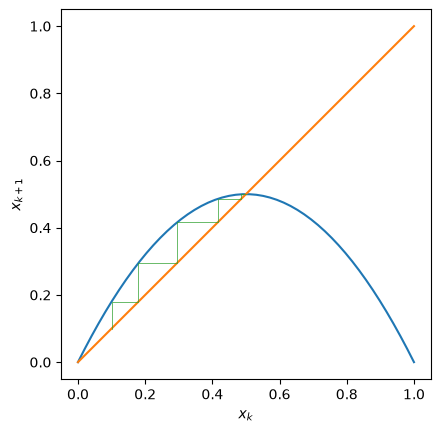

In [7]:
a = 2
xt = iterate(logistic, 0.1, a, 200)
plt.plot(x, logistic(x, a))  # plot the map
cobsplot(xt)  # plot the trajectory

x = 0 is unstable; x = 0.5 is stable

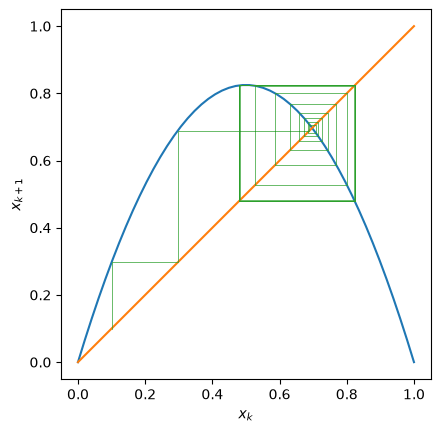

In [8]:
a = 3.3
xt = iterate(logistic, 0.1, a, 200)
plt.plot(x, logistic(x, a))  # plot the map
cobsplot(xt)  # plot the trajectory

x = 0 is unstable; x = 0.697 is stable

if $|f'(x_k) = -2ax_k + a| < 1$, $x_k$ is stable

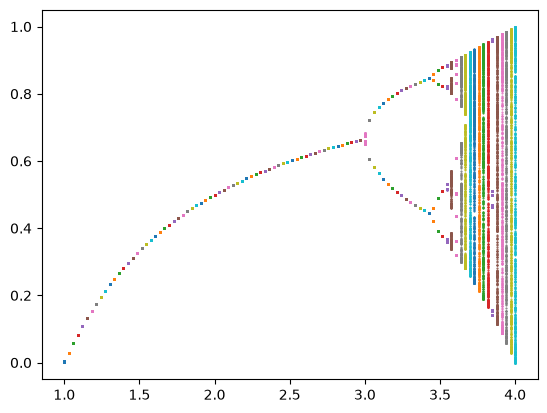

In [31]:
a_list = np.linspace(1, 4, 100)
for a in a_list:
    xt = iterate(logistic, 0.1, a, 1000)
    xt_last = xt[200:]
    plt.scatter([a]*len(xt_last), xt_last, s=0.3)
    

## 3. Recursive call and fractal

Draw the *Sherpinski gasket* like below.

![shelpinski](https://github.com/oist/iSciComp/blob/master/figures/shelpinski.png?raw=1)

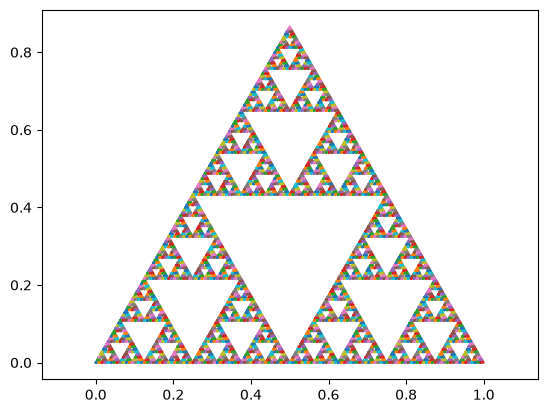

In [45]:
def sherpinski(x0=[0,0], x1=[1,0], e=1e-2):
    """draw a fractal line
    x0, x1: start, end points
    e: minimal resolution"""
    u = x1[0] - x0[0]   # connecting vector
    if u**2 < e**2: # if the segment is very short
        plt.plot([x0[0], x1[0], x0[0]+u/2, x0[0]], [x0[1], x1[1], x0[1]+u*np.sqrt(3)/2, x0[1]])
    else:
        sherpinski([x0[0], x0[1]], [x0[0]+u/2, x0[1]], e)
        sherpinski([x0[0]+u/2, x0[1]], [x1[0], x1[1]], e)
        sherpinski([x0[0]+u/4, x0[1]+u*np.sqrt(3)/4], [x0[0]+3*u/4, x0[1]+u*np.sqrt(3)/4], e)
    plt.axis('equal');

sherpinski([0,0], [1,0], 0.01)